# Haryana Mandi Insights
## Agricultural Price Analysis and Forecasting
### Notebook 4 — Model Training and Price Forecasting

---

**Course:** Advanced Data Science
**Dataset:** Haryana Mandi Agricultural Price Data (2022–2026)
**Input:** Haryana_Mandi_Cleaned.csv + monthly_modal_prices.csv


## Model Training Objectives

| Section | Content |
|---|---|
| 1 | Dataset overview for selected commodity |
| 2 | Baseline models — Naive and Seasonal Naive |
| 3 | Feature engineering — lag and rolling features |
| 4 | Train/test split |
| 5 | ML models — Linear Regression, Random Forest, Gradient Boosting, XGBoost |
| 6 | Model evaluation — MAE, RMSE, MAPE, R² |
| 7 | Residual diagnostics |
| 8 | Model comparison scorecard |
| 9 | Cross validation |
| 10 | Feature importance |
| 11 | 6-month future forecast |
| 12 | Save all outputs |
| 13 | Final model conclusions |

---

## Hypothesis H3

- **H0:** ML models do not outperform a naive baseline forecast
- **H1:** ML models produce lower RMSE than the naive baseline
- **Decision rule:** If best ML RMSE < Naive RMSE → H1 supported

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted")

Mounted at /content/drive
Google Drive mounted


In [2]:
# Install Libraries
!pip install xgboost --quiet
!pip install scikit-learn --quiet
print("Libraries installed")

Libraries installed


In [4]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os
import warnings

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (RandomForestRegressor,
                               GradientBoostingRegressor)
from sklearn.metrics import (mean_absolute_error,
                              mean_squared_error, r2_score)
from sklearn.model_selection import cross_val_score
import xgboost as xgb

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
# Define Paths
BASE_PATH      = '/content/drive/MyDrive/Haryana_Mandi_Project/'
PROCESSED_PATH = BASE_PATH + 'Data/Processed/'
MODELS_PATH    = BASE_PATH + 'Models/'
IMAGES_MODEL   = BASE_PATH + 'Images/Models/'

for path in [PROCESSED_PATH, MODELS_PATH, IMAGES_MODEL]:
    os.makedirs(path, exist_ok=True)

print(" Paths defined")
print(f"   Processed : {PROCESSED_PATH}")
print(f"   Models    : {MODELS_PATH}")
print(f"   Images    : {IMAGES_MODEL}")

 Paths defined
   Processed : /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   Models    : /content/drive/MyDrive/Haryana_Mandi_Project/Models/
   Images    : /content/drive/MyDrive/Haryana_Mandi_Project/Images/Models/


In [6]:
# Load Data
df = pd.read_csv(PROCESSED_PATH + 'Haryana_Mandi_Cleaned.csv',
                 parse_dates=['Arrival_Date'])

monthly_df = pd.read_csv(PROCESSED_PATH + 'monthly_modal_prices.csv')
monthly_df['Month'] = pd.to_datetime(monthly_df['Month'])

print(f" Main data     : {df.shape[0]:,} rows")
print(f" Monthly data  : {monthly_df.shape[0]:,} rows")
df.head(3)

 Main data     : 133,720 rows
 Monthly data  : 2,499 rows


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
0,2023-04-26,Mustard,12,Hissar,FAQ,Adampur,5450,4381.0000,4650.0000,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,1069.0000,False
1,2023-04-28,Mustard,12,Hissar,FAQ,Adampur,4890,4011.0000,4664.0000,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,879.0000,False
2,2023-05-02,Mustard,12,Hissar,FAQ,Adampur,4899,4151.0000,4500.0000,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,18,Zaid,748.0000,False


## Section 1 — Dataset Overview for Selected Commodity

We select **Wheat** as the primary commodity for forecasting because:
- It is the most widely traded commodity in Haryana mandis
- It has the highest number of monthly observations
- It has clear seasonal patterns suitable for forecasting
- It is the primary Rabi crop and of strategic importance

The target variable is **Modal Price (₹/Quintal)** aggregated
to monthly averages.

In [7]:
# Commodity Dataset Overview
COMMODITY = 'Wheat'

ts = monthly_df[monthly_df['Commodity'] == COMMODITY]\
         .sort_values('Month').reset_index(drop=True)

print("═"*55)
print(f"    COMMODITY OVERVIEW — {COMMODITY}")
print("═"*55)
print(f"Total monthly observations : {len(ts)}")
print(f"Date range                 : {ts['Month'].min().date()} "
      f"→ {ts['Month'].max().date()}")

# Check for missing months
all_months   = pd.date_range(ts['Month'].min(),
                              ts['Month'].max(), freq='MS')
actual_months = pd.to_datetime(ts['Month'].values)
missing_months = set(all_months) - set(actual_months)
print(f"Missing months             : {len(missing_months)}")
if missing_months:
    print(f"Missing: {sorted(missing_months)}")

print(f"\nDescriptive Statistics:")
print(ts['Modal_Price'].describe().round(2))
print("═"*55)
ts.head(8)

═══════════════════════════════════════════════════════
    COMMODITY OVERVIEW — Wheat
═══════════════════════════════════════════════════════
Total monthly observations : 19
Date range                 : 2023-04-01 → 2026-05-01
Missing months             : 19
Missing: [Timestamp('2023-07-01 00:00:00'), Timestamp('2023-08-01 00:00:00'), Timestamp('2023-10-01 00:00:00'), Timestamp('2023-11-01 00:00:00'), Timestamp('2023-12-01 00:00:00'), Timestamp('2024-02-01 00:00:00'), Timestamp('2024-03-01 00:00:00'), Timestamp('2024-08-01 00:00:00'), Timestamp('2024-12-01 00:00:00'), Timestamp('2025-01-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2025-07-01 00:00:00'), Timestamp('2025-08-01 00:00:00'), Timestamp('2025-10-01 00:00:00'), Timestamp('2025-11-01 00:00:00'), Timestamp('2025-12-01 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-02-01 00:00:00'), Timestamp('2026-03-01 00:00:00')]

Descriptive Statistics:
count     19.0000
mean    2399.1000
std      188.0400
min  

,Commodity,Month,Modal_Price
0,Wheat,2023-04-01,2125.5217
1,Wheat,2023-05-01,2134.9262
2,Wheat,2023-06-01,2209.8333
3,Wheat,2023-09-01,2123.0000
4,Wheat,2024-01-01,2300.0000
5,Wheat,2024-04-01,2275.2520
6,Wheat,2024-05-01,2275.3643
7,Wheat,2024-06-01,2313.3333


## Section 2 — Baseline Models

Before training ML models, we establish baseline forecasts
to set a performance benchmark.

### Naive Forecast
Predicts the next month's price as equal to the current month's price.
This is the simplest possible forecast.
`Prediction(t+1) = Actual(t)`

### Seasonal Naive Forecast
Predicts the next month's price as equal to the same month
from the previous year.
`Prediction(t) = Actual(t - 12)`

ML models must outperform these baselines to be considered useful.

In [8]:
# Baseline Models
TEST_SIZE = 6

# Naive forecast — last known value
naive_preds    = ts['Modal_Price'].shift(1).iloc[-TEST_SIZE:].values
naive_actuals  = ts['Modal_Price'].iloc[-TEST_SIZE:].values
naive_dates    = ts['Month'].iloc[-TEST_SIZE:].values

# Seasonal naive — same month last year (12 months back)
seasonal_preds = ts['Modal_Price'].shift(12).iloc[-TEST_SIZE:].values

def evaluate(actuals, preds, name):
    # Handle zero values in MAPE
    mask  = actuals != 0
    mae   = mean_absolute_error(actuals, preds)
    rmse  = np.sqrt(mean_squared_error(actuals, preds))
    mape  = np.mean(np.abs((actuals[mask] - preds[mask]) /
                            actuals[mask])) * 100
    r2    = r2_score(actuals, preds)
    print(f"{'─'*45}")
    print(f"Model  : {name}")
    print(f"MAE    : ₹{mae:.2f}")
    print(f"RMSE   : ₹{rmse:.2f}")
    print(f"MAPE   : {mape:.2f}%")
    print(f"R²     : {r2:.4f}")
    return {'Model': name, 'MAE': mae, 'RMSE': rmse,
            'MAPE_%': mape, 'R2': r2}

print("BASELINE MODEL EVALUATION")
naive_res    = evaluate(naive_actuals, naive_preds,
                        'Naive Forecast')

# Only run seasonal naive if enough data
if not np.isnan(seasonal_preds).any():
    seasonal_res = evaluate(naive_actuals, seasonal_preds,
                            'Seasonal Naive')
else:
    print("─"*45)
    print("Seasonal Naive: insufficient history (need 12+ months)")
    seasonal_res = {'Model': 'Seasonal Naive',
                    'MAE': np.nan, 'RMSE': np.nan,
                    'MAPE_%': np.nan, 'R2': np.nan}

BASELINE MODEL EVALUATION
─────────────────────────────────────────────
Model  : Naive Forecast
MAE    : ₹43.98
RMSE   : ₹58.75
MAPE   : 1.76%
R²     : 0.3555
─────────────────────────────────────────────
Model  : Seasonal Naive
MAE    : ₹269.00
RMSE   : ₹272.56
MAPE   : 10.80%
R²     : -12.8738


## Section 3 — Feature Engineering

Time series forecasting with ML requires transforming the
sequential data into a supervised learning format.

### Features Created

| Feature | Description |
|---|---|
| Year | Calendar year |
| Month_N | Month number (1–12) |
| Quarter | Calendar quarter (1–4) |
| Lag_1 | Modal price from 1 month ago |
| Lag_2 | Modal price from 2 months ago |
| Lag_3 | Modal price from 3 months ago |
| Lag_6 | Modal price from 6 months ago |
| Roll_Mean_3 | 3-month rolling average of past prices |
| Roll_Mean_6 | 6-month rolling average of past prices |
| Roll_Std_3 | 3-month rolling standard deviation |
| Momentum | Lag_1 minus Lag_3 (price direction) |

Lag features allow the model to learn from past prices.
Rolling features capture recent trends and volatility.

In [9]:
# Feature Engineering
def create_features(df_ts):
    df_ts = df_ts.copy()
    df_ts['Year']        = df_ts['Month'].dt.year
    df_ts['Month_N']     = df_ts['Month'].dt.month
    df_ts['Quarter']     = df_ts['Month'].dt.quarter
    for lag in [1, 2, 3, 6]:
        df_ts[f'Lag_{lag}'] = df_ts['Modal_Price'].shift(lag)
    df_ts['Roll_Mean_3'] = df_ts['Modal_Price']\
                            .shift(1).rolling(3).mean()
    df_ts['Roll_Mean_6'] = df_ts['Modal_Price']\
                            .shift(1).rolling(6).mean()
    df_ts['Roll_Std_3']  = df_ts['Modal_Price']\
                            .shift(1).rolling(3).std()
    df_ts['Momentum']    = df_ts['Modal_Price'].shift(1) - \
                           df_ts['Modal_Price'].shift(3)
    df_ts.dropna(inplace=True)
    df_ts.reset_index(drop=True, inplace=True)
    return df_ts

ts_feat = create_features(ts)

print(f"Rows after feature engineering : {len(ts_feat)}")
print(f"Features created               : {ts_feat.columns.tolist()}")
ts_feat.head(5)

Rows after feature engineering : 13
Features created               : ['Commodity', 'Month', 'Modal_Price', 'Year', 'Month_N', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_6', 'Roll_Mean_3', 'Roll_Mean_6', 'Roll_Std_3', 'Momentum']


,Commodity,Month,Modal_Price,Year,Month_N,Quarter,Lag_1,Lag_2,Lag_3,Lag_6,Roll_Mean_3,Roll_Mean_6,Roll_Std_3,Momentum
0,Wheat,2024-05-01,2275.3643,2024,5,2,2275.2520,2300.0000,2123.0000,2125.5217,2232.7507,2194.7555,95.8489,152.2520
1,Wheat,2024-06-01,2313.3333,2024,6,2,2275.3643,2275.2520,2300.0000,2134.9262,2283.5388,2219.7293,14.2560,-24.6357
2,Wheat,2024-07-01,2413.3333,2024,7,3,2313.3333,2275.3643,2275.2520,2209.8333,2287.9832,2249.4638,21.9539,38.0814
3,Wheat,2024-09-01,2515.0000,2024,9,3,2413.3333,2313.3333,2275.3643,2123.0000,2334.0103,2283.3805,71.2707,137.9690
4,Wheat,2024-10-01,2680.0000,2024,10,4,2515.0000,2413.3333,2313.3333,2300.0000,2413.8889,2348.7138,100.8345,201.6667


In [10]:
# Train / Test Split
FEATURES = ['Year', 'Month_N', 'Quarter',
            'Lag_1', 'Lag_2', 'Lag_3', 'Lag_6',
            'Roll_Mean_3', 'Roll_Mean_6',
            'Roll_Std_3', 'Momentum']
TARGET   = 'Modal_Price'

train = ts_feat.iloc[:-TEST_SIZE]
test  = ts_feat.iloc[-TEST_SIZE:]

X_train = train[FEATURES]
y_train = train[TARGET]
X_test  = test[FEATURES]
y_test  = test[TARGET]

print("═"*55)
print("         TRAIN / TEST SPLIT")
print("═"*55)
print(f"Total observations : {len(ts_feat)}")
print(f"Train size         : {len(train)} months")
print(f"Test size          : {len(test)} months")
print(f"Train period       : {train['Month'].min().date()} "
      f"→ {train['Month'].max().date()}")
print(f"Test period        : {test['Month'].min().date()} "
      f"→ {test['Month'].max().date()}")
print(f"Features           : {len(FEATURES)}")
print("═"*55)

═══════════════════════════════════════════════════════
         TRAIN / TEST SPLIT
═══════════════════════════════════════════════════════
Total observations : 13
Train size         : 7 months
Test size          : 6 months
Train period       : 2024-05-01 → 2025-03-01
Test period        : 2025-04-01 → 2026-05-01
Features           : 11
═══════════════════════════════════════════════════════


In [12]:
# Train All ML Models
models = {
    'Linear Regression' : LinearRegression(),
    'Random Forest'     : RandomForestRegressor(
                            n_estimators=200, random_state=42),
    'Gradient Boosting' : GradientBoostingRegressor(
                            n_estimators=200, random_state=42),
    'XGBoost'           : xgb.XGBRegressor(
                            n_estimators=200, random_state=42,
                            verbosity=0)
}

all_results = {}
all_preds   = {}

print("ML MODEL EVALUATION")
for name, model in models.items():
    model.fit(X_train, y_train)
    preds  = model.predict(X_test)
    result = evaluate(y_test.values, preds, name)
    all_results[name] = result
    all_preds[name]   = preds

print(f"\n All models trained successfully")

ML MODEL EVALUATION
─────────────────────────────────────────────
Model  : Linear Regression
MAE    : ₹687.60
RMSE   : ₹889.28
MAPE   : 27.89%
R²     : -146.6853
─────────────────────────────────────────────
Model  : Random Forest
MAE    : ₹77.17
RMSE   : ₹82.40
MAPE   : 3.13%
R²     : -0.2679
─────────────────────────────────────────────
Model  : Gradient Boosting
MAE    : ₹61.85
RMSE   : ₹68.34
MAPE   : 2.47%
R²     : 0.1278
─────────────────────────────────────────────
Model  : XGBoost
MAE    : ₹81.86
RMSE   : ₹82.06
MAPE   : 3.29%
R²     : -0.2575

 All models trained successfully


In [15]:
# Full Model Scorecard
all_model_results = [naive_res, seasonal_res] + \
                    list(all_results.values())

scorecard_df = pd.DataFrame(all_model_results)\
                 .set_index('Model')\
                 .round(3)\
                 .sort_values('RMSE')

print("═"*65)
print("              FULL MODEL COMPARISON SCORECARD")
print("═"*65)
print(scorecard_df.to_string())
print("═"*65)

best_ml_name = min(all_results,
                   key=lambda x: all_results[x]['RMSE'])
best_ml_rmse = all_results[best_ml_name]['RMSE']
naive_rmse   = naive_res['RMSE']
improvement  = ((naive_rmse - best_ml_rmse) / naive_rmse) * 100

print(f"\nBest ML Model     : {best_ml_name}")
print(f"Naive RMSE        : ₹{naive_rmse:.2f}")
print(f"Best ML RMSE      : ₹{best_ml_rmse:.2f}")
print(f"RMSE Improvement  : {improvement:.2f}%")
print()
if best_ml_rmse < naive_rmse:
    print("H3 SUPPORTED — ML model outperforms naive baseline")
else:
    print("H3 NOT SUPPORTED — ML model does not outperform baseline")

═════════════════════════════════════════════════════════════════
              FULL MODEL COMPARISON SCORECARD
═════════════════════════════════════════════════════════════════
                       MAE     RMSE  MAPE_%        R2
Model                                                
Naive Forecast     43.9770  58.7450  1.7590    0.3560
Gradient Boosting  61.8510  68.3380  2.4720    0.1280
XGBoost            81.8590  82.0590  3.2890   -0.2580
Random Forest      77.1700  82.3970  3.1290   -0.2680
Seasonal Naive    268.9980 272.5630 10.7990  -12.8740
Linear Regression 687.6000 889.2790 27.8860 -146.6850
═════════════════════════════════════════════════════════════════

Best ML Model     : Gradient Boosting
Naive RMSE        : ₹58.75
Best ML RMSE      : ₹68.34
RMSE Improvement  : -16.33%

H3 NOT SUPPORTED — ML model does not outperform baseline


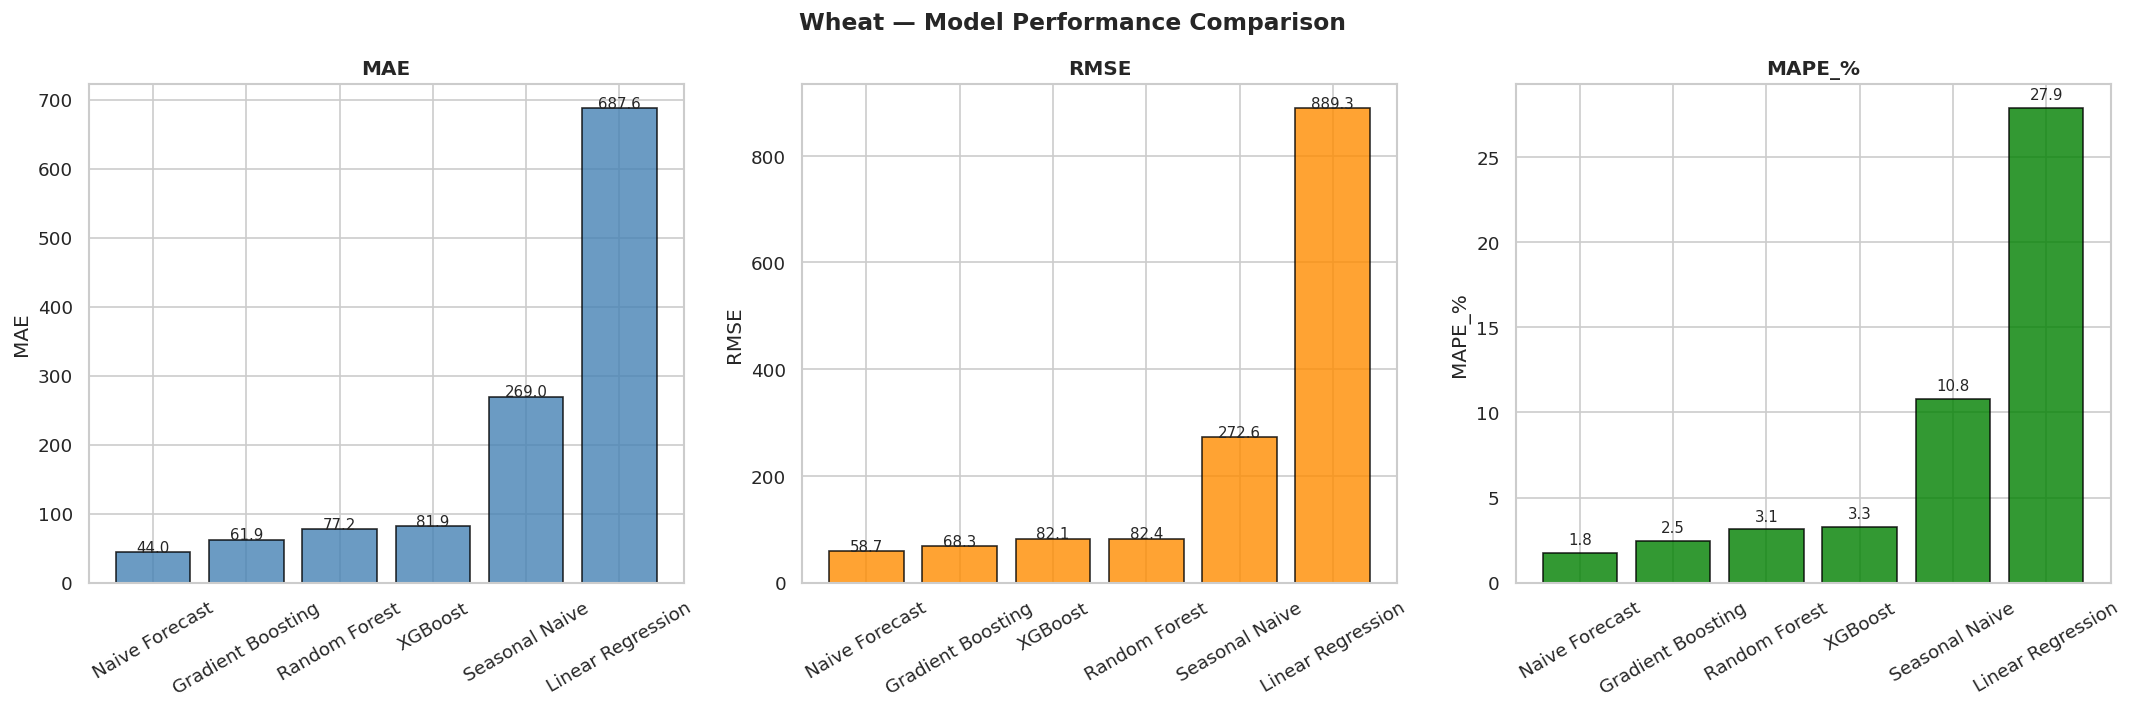

In [16]:
# Model Comparison Bar Charts
metrics = ['MAE', 'RMSE', 'MAPE_%']
colors  = ['steelblue', 'darkorange', 'green']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (metric, color) in enumerate(zip(metrics, colors)):
    data = scorecard_df[metric].dropna().sort_values()
    bars = axes[i].bar(data.index, data.values,
                       color=color, edgecolor='black', alpha=0.8)
    axes[i].set_title(f'{metric}', fontweight='bold')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=30)
    for bar, val in zip(bars, data.values):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 0.5,
                     f'{val:.1f}', ha='center', fontsize=9)

plt.suptitle(f'{COMMODITY} — Model Performance Comparison',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL + f'ml_{COMMODITY}_model_comparison.png',
            bbox_inches='tight')
plt.show()

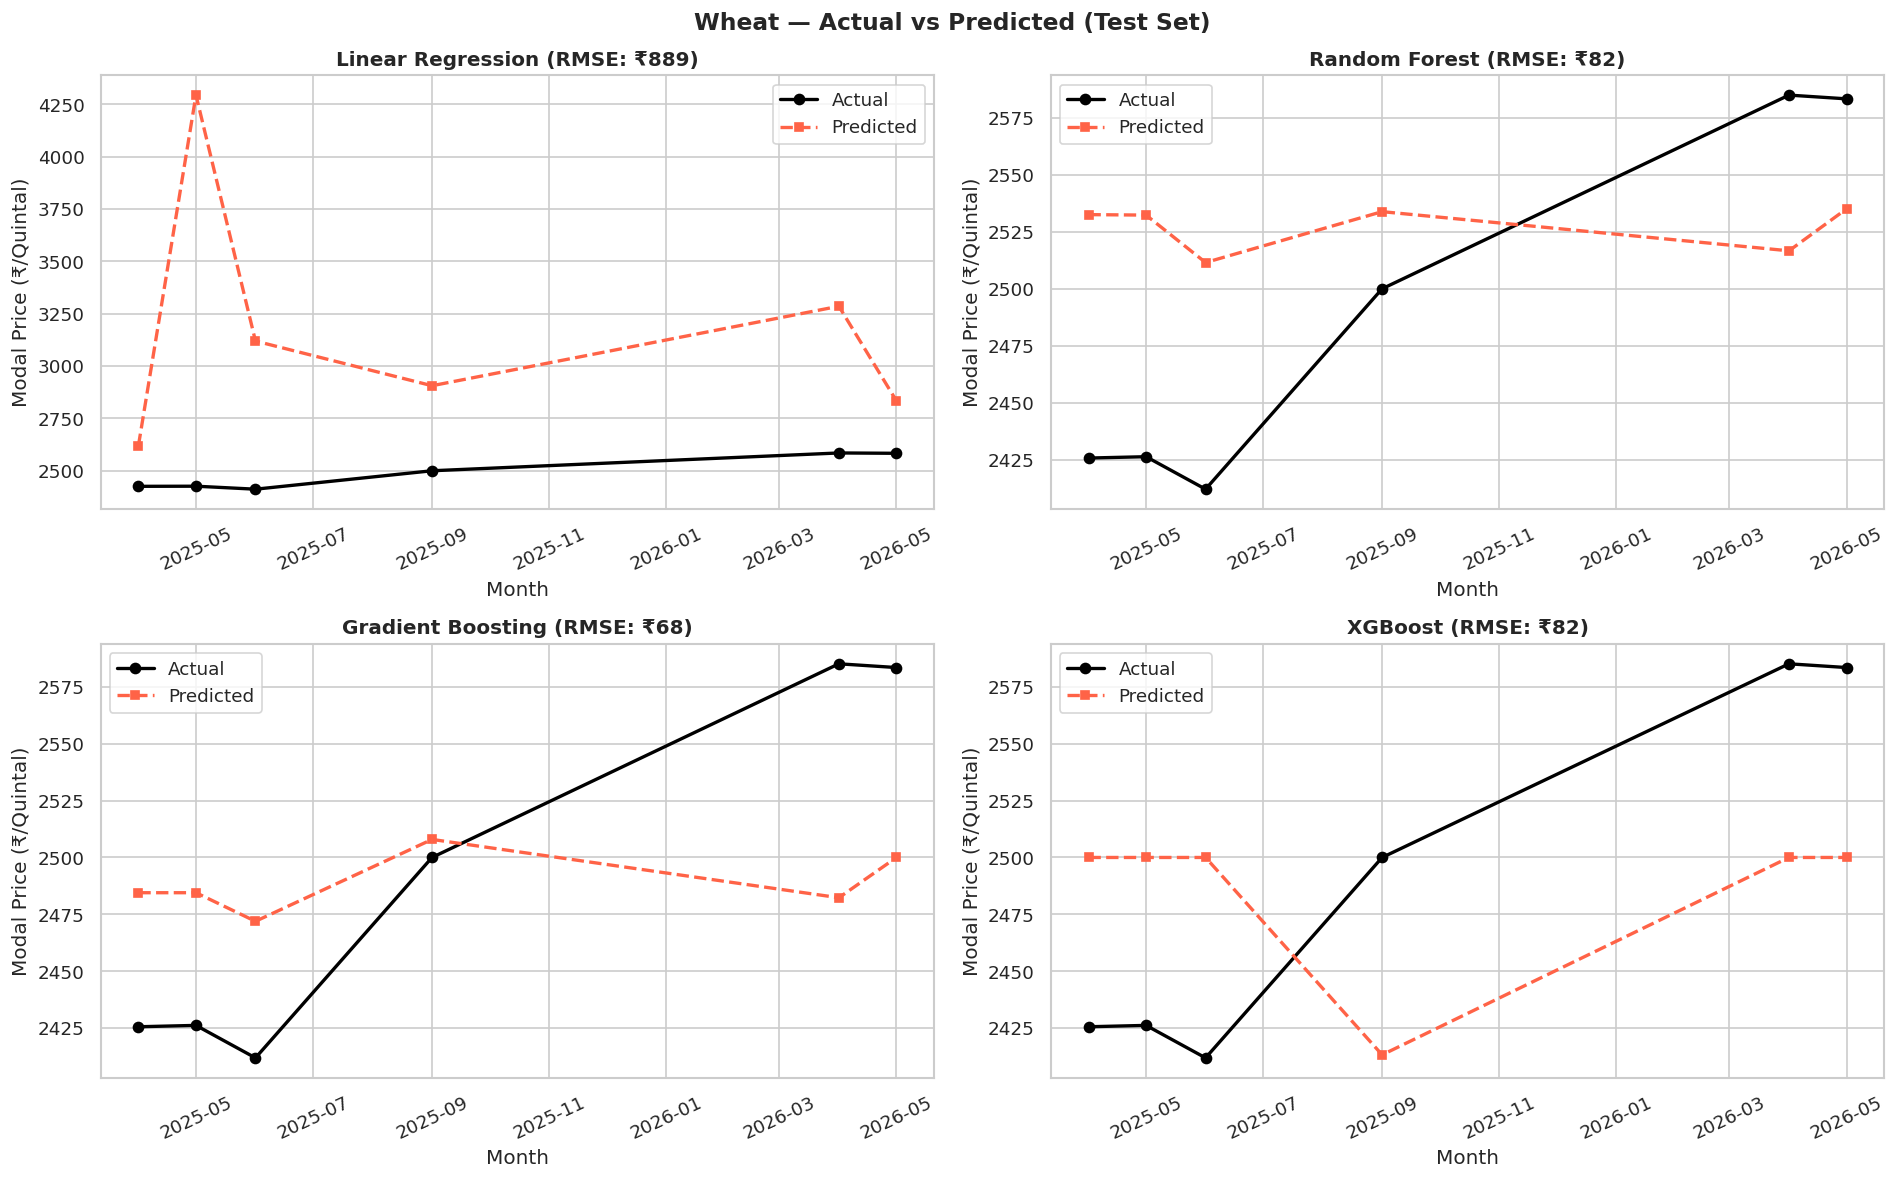

In [17]:
# Actual vs Predicted — All Models
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes      = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    axes[i].plot(test['Month'].values, y_test.values,
                 label='Actual', color='black',
                 linewidth=2, marker='o', markersize=6)
    axes[i].plot(test['Month'].values, preds,
                 label='Predicted', color='tomato',
                 linewidth=2, marker='s', markersize=5,
                 linestyle='--')
    rmse = all_results[name]['RMSE']
    axes[i].set_title(f'{name} (RMSE: ₹{rmse:.0f})',
                       fontweight='bold')
    axes[i].set_xlabel('Month')
    axes[i].set_ylabel('Modal Price (₹/Quintal)')
    axes[i].legend()
    axes[i].tick_params(axis='x', rotation=25)

plt.suptitle(f'{COMMODITY} — Actual vs Predicted (Test Set)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL +
            f'ml_{COMMODITY}_actual_vs_predicted.png',
            bbox_inches='tight')
plt.show()

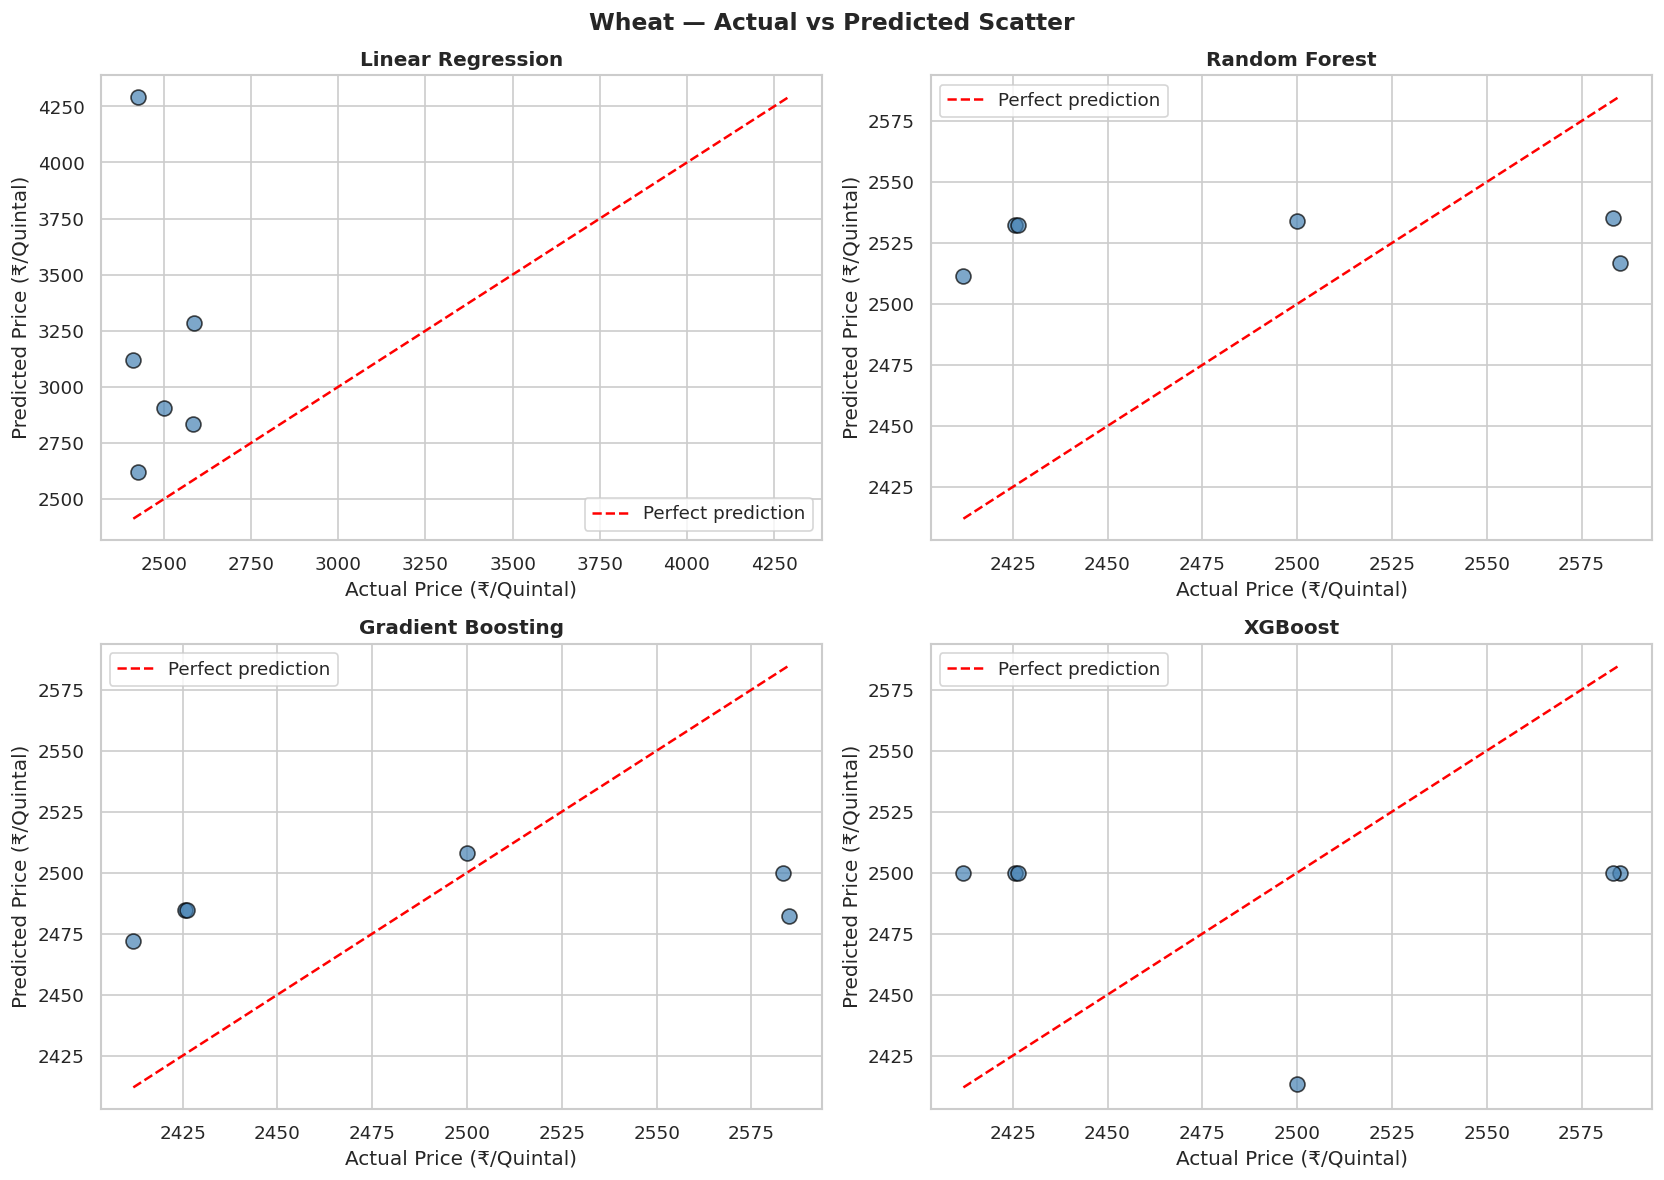


Interpretation:
Points close to the red diagonal line indicate accurate predictions.
Points above the line mean the model over-predicted.
Points below the line mean the model under-predicted.



In [18]:
# Actual vs Predicted Scatter Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes      = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    axes[i].scatter(y_test.values, preds,
                    color='steelblue', alpha=0.7,
                    edgecolors='black', s=80)
    min_val = min(y_test.min(), preds.min())
    max_val = max(y_test.max(), preds.max())
    axes[i].plot([min_val, max_val], [min_val, max_val],
                 color='red', linestyle='--', linewidth=1.5,
                 label='Perfect prediction')
    axes[i].set_title(f'{name}', fontweight='bold')
    axes[i].set_xlabel('Actual Price (₹/Quintal)')
    axes[i].set_ylabel('Predicted Price (₹/Quintal)')
    axes[i].legend()

plt.suptitle(f'{COMMODITY} — Actual vs Predicted Scatter',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL +
            f'ml_{COMMODITY}_scatter_plots.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Points close to the red diagonal line indicate accurate predictions.
Points above the line mean the model over-predicted.
Points below the line mean the model under-predicted.
""")

## Section 7 — Residual Diagnostics

Residuals = Actual − Predicted

A good model should have residuals that:
- Are centred around zero (no systematic bias)
- Show no pattern over time (random noise)
- Follow an approximately normal distribution
- Show no relationship with predicted values (homoscedasticity)

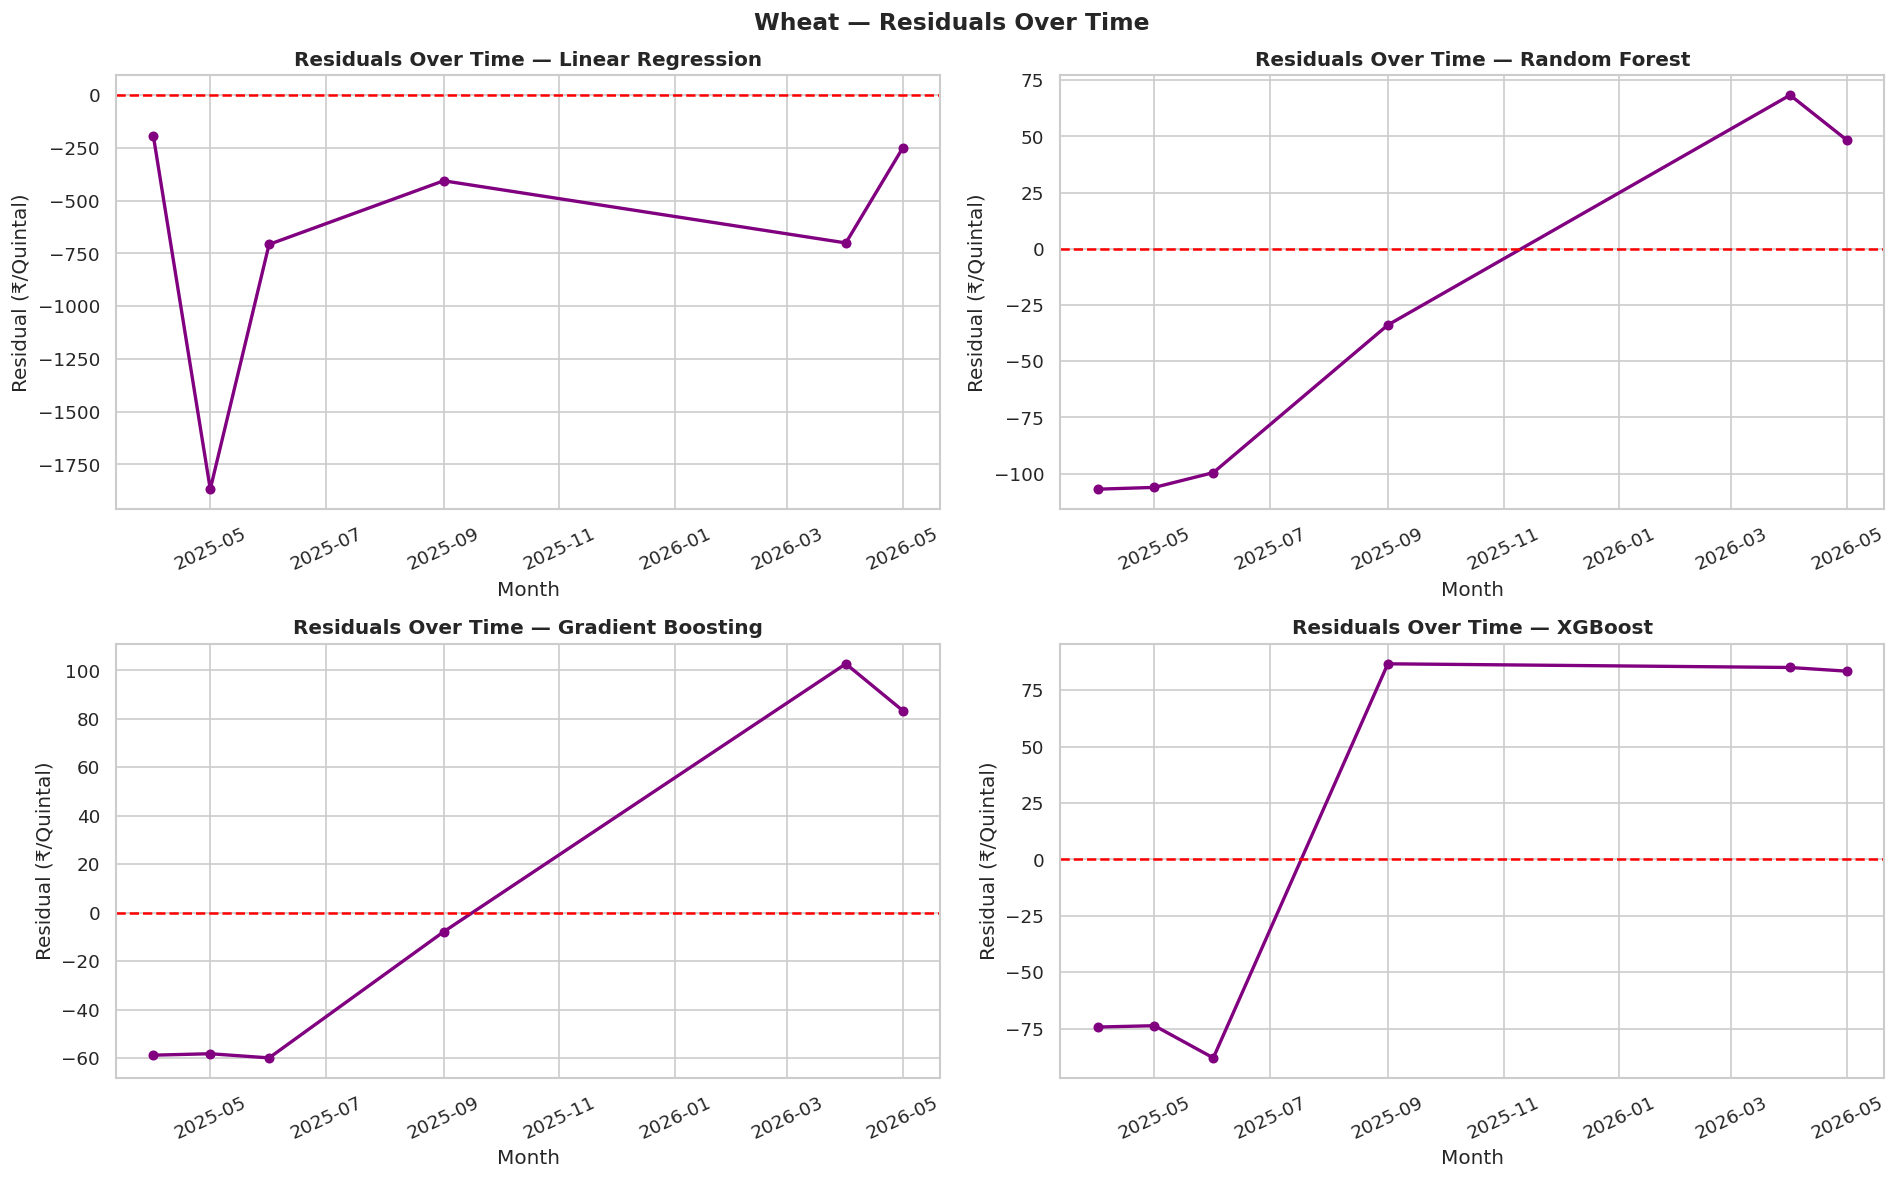

In [19]:
# Residuals Over Time
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes      = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    residuals = y_test.values - preds
    axes[i].plot(test['Month'].values, residuals,
                 color='purple', linewidth=2,
                 marker='o', markersize=5)
    axes[i].axhline(0, color='red', linestyle='--',
                    linewidth=1.5)
    axes[i].set_title(f'Residuals Over Time — {name}',
                       fontweight='bold')
    axes[i].set_xlabel('Month')
    axes[i].set_ylabel('Residual (₹/Quintal)')
    axes[i].tick_params(axis='x', rotation=25)

plt.suptitle(f'{COMMODITY} — Residuals Over Time',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL +
            f'ml_{COMMODITY}_residuals_time.png',
            bbox_inches='tight')
plt.show()

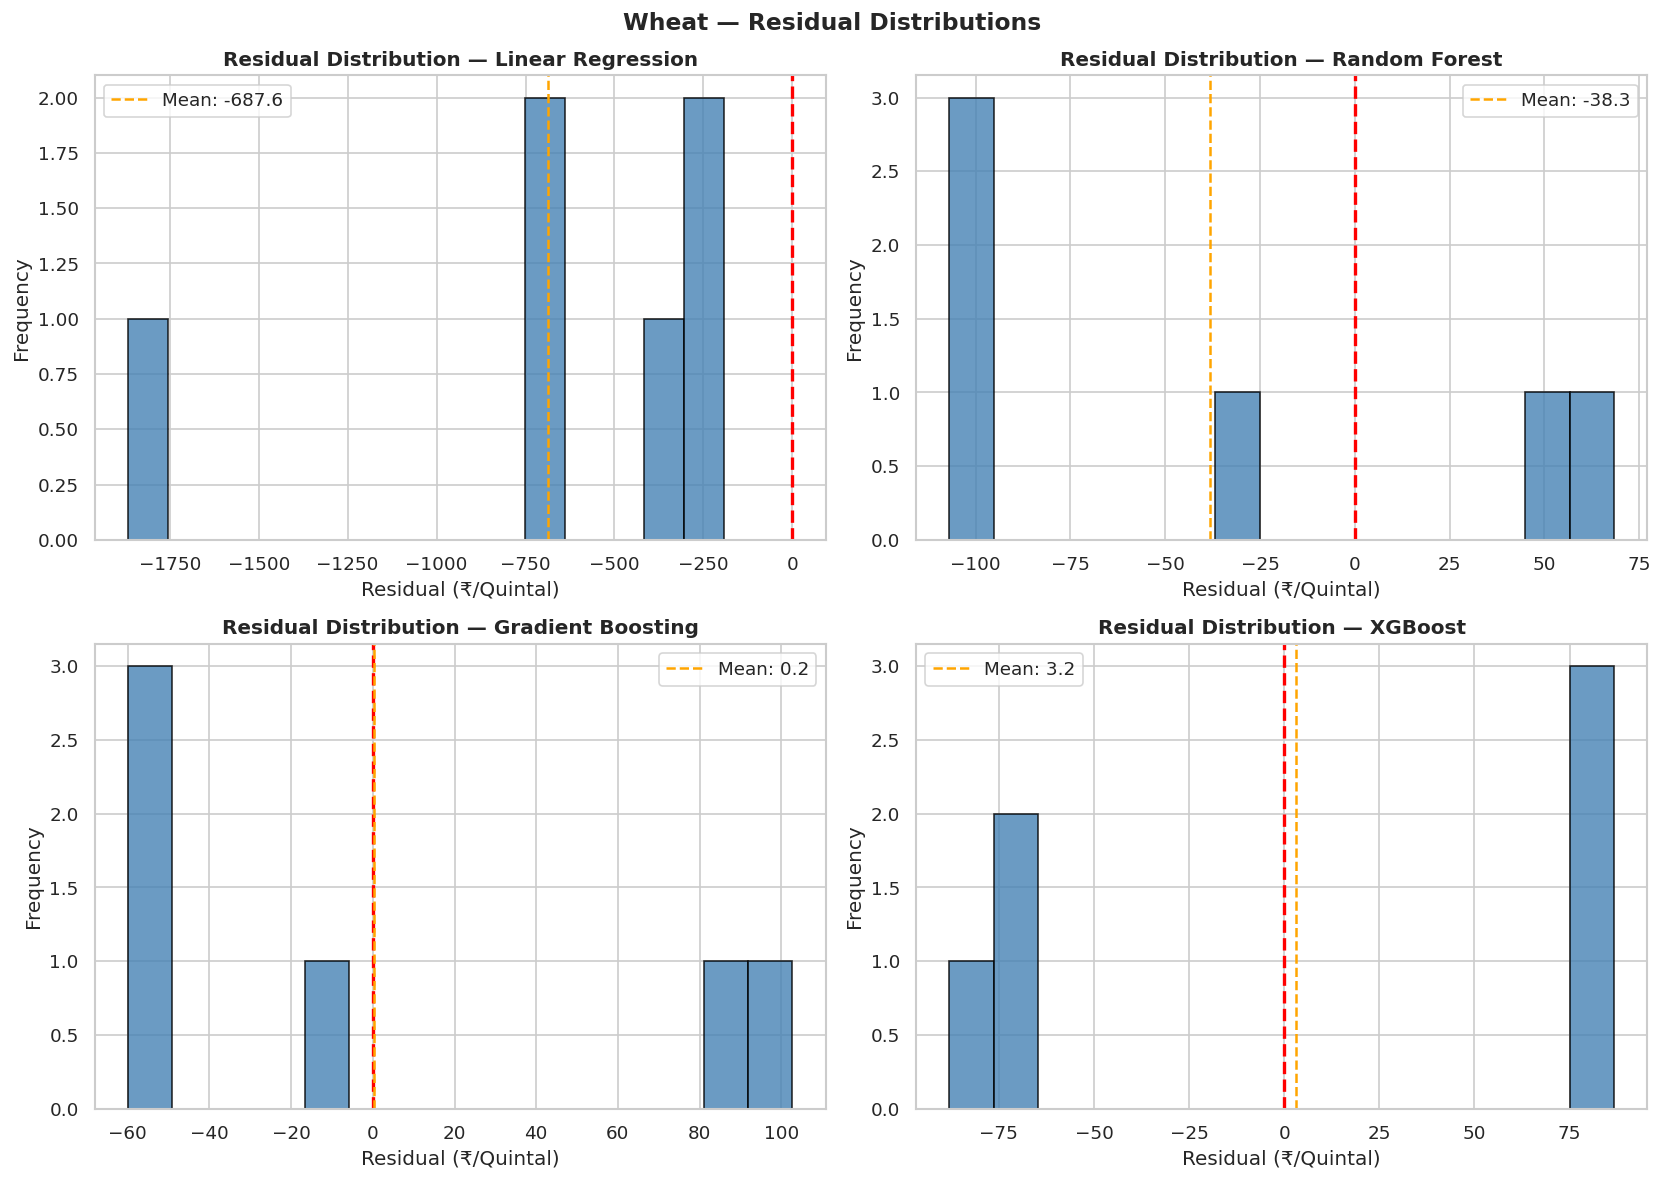

In [20]:
# Residual Distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes      = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    residuals = y_test.values - preds
    axes[i].hist(residuals, bins=15, color='steelblue',
                 edgecolor='black', alpha=0.8)
    axes[i].axvline(0, color='red', linestyle='--',
                    linewidth=2)
    axes[i].axvline(residuals.mean(), color='orange',
                    linestyle='--', linewidth=1.5,
                    label=f"Mean: {residuals.mean():.1f}")
    axes[i].set_title(f'Residual Distribution — {name}',
                       fontweight='bold')
    axes[i].set_xlabel('Residual (₹/Quintal)')
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.suptitle(f'{COMMODITY} — Residual Distributions',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL +
            f'ml_{COMMODITY}_residual_distribution.png',
            bbox_inches='tight')
plt.show()

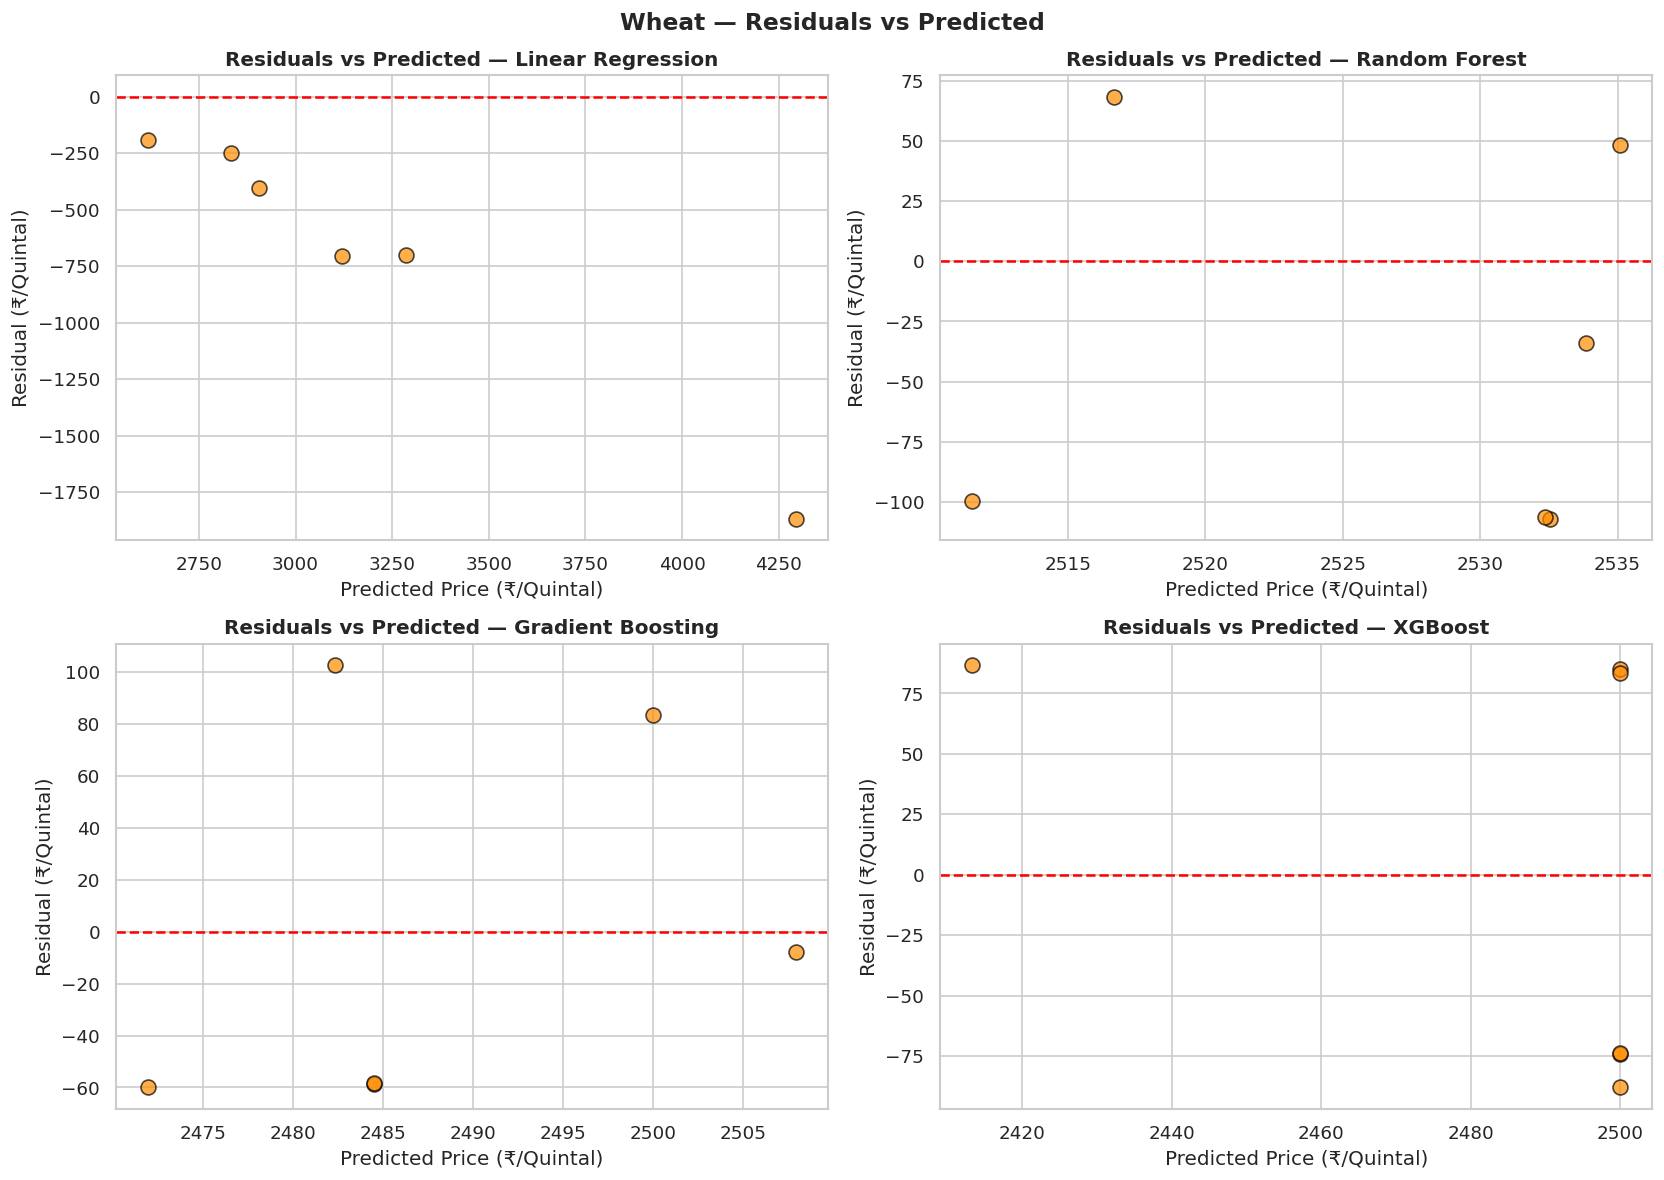


Interpretation:
No pattern in the residual vs predicted plot indicates
homoscedasticity — the model errors are consistent across
all price levels. A funnel shape would indicate that the
model struggles more at higher or lower price levels.



In [21]:
# Residuals vs Predicted Values
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes      = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    residuals = y_test.values - preds
    axes[i].scatter(preds, residuals,
                    color='darkorange', alpha=0.7,
                    edgecolors='black', s=80)
    axes[i].axhline(0, color='red', linestyle='--',
                    linewidth=1.5)
    axes[i].set_title(f'Residuals vs Predicted — {name}',
                       fontweight='bold')
    axes[i].set_xlabel('Predicted Price (₹/Quintal)')
    axes[i].set_ylabel('Residual (₹/Quintal)')

plt.suptitle(f'{COMMODITY} — Residuals vs Predicted',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_MODEL +
            f'ml_{COMMODITY}_residuals_vs_predicted.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
No pattern in the residual vs predicted plot indicates
homoscedasticity — the model errors are consistent across
all price levels. A funnel shape would indicate that the
model struggles more at higher or lower price levels.
""")

## Section 9 — Time Series Cross Validation

Standard k-fold cross validation randomly shuffles data,
which is invalid for time series because it leaks future
information into training.

We use **expanding window cross validation** where:
- Each fold adds one more month to the training set
- The test set is always the next month
- This simulates real forecasting conditions

This is only performed when sufficient observations exist.

In [22]:
# Expanding Window Cross Validation
min_train = 10
n_obs     = len(ts_feat)
cv_results = {name: [] for name in models.keys()}

print("Expanding Window Cross Validation")
print(f"Min training size : {min_train}")
print(f"Total folds       : {n_obs - min_train}")
print()

for fold in range(min_train, n_obs):
    X_cv_train = ts_feat[FEATURES].iloc[:fold]
    y_cv_train = ts_feat[TARGET].iloc[:fold]
    X_cv_test  = ts_feat[FEATURES].iloc[[fold]]
    y_cv_test  = ts_feat[TARGET].iloc[[fold]]

    for name, model in models.items():
        model.fit(X_cv_train, y_cv_train)
        pred = model.predict(X_cv_test)[0]
        rmse = np.sqrt((y_cv_test.values[0] - pred)**2)
        cv_results[name].append(rmse)

cv_summary = pd.DataFrame({
    'Model'      : list(cv_results.keys()),
    'CV_RMSE_Mean': [np.mean(v) for v in cv_results.values()],
    'CV_RMSE_Std' : [np.std(v)  for v in cv_results.values()]
}).round(2).sort_values('CV_RMSE_Mean')

print("Cross Validation Results (Expanding Window):")
print(cv_summary.to_string(index=False))

Expanding Window Cross Validation
Min training size : 10
Total folds       : 3

Cross Validation Results (Expanding Window):
            Model  CV_RMSE_Mean  CV_RMSE_Std
    Random Forest       72.0500      37.8300
          XGBoost       75.8500      57.6600
Gradient Boosting       82.6100      47.5100
Linear Regression      154.9800      44.5900


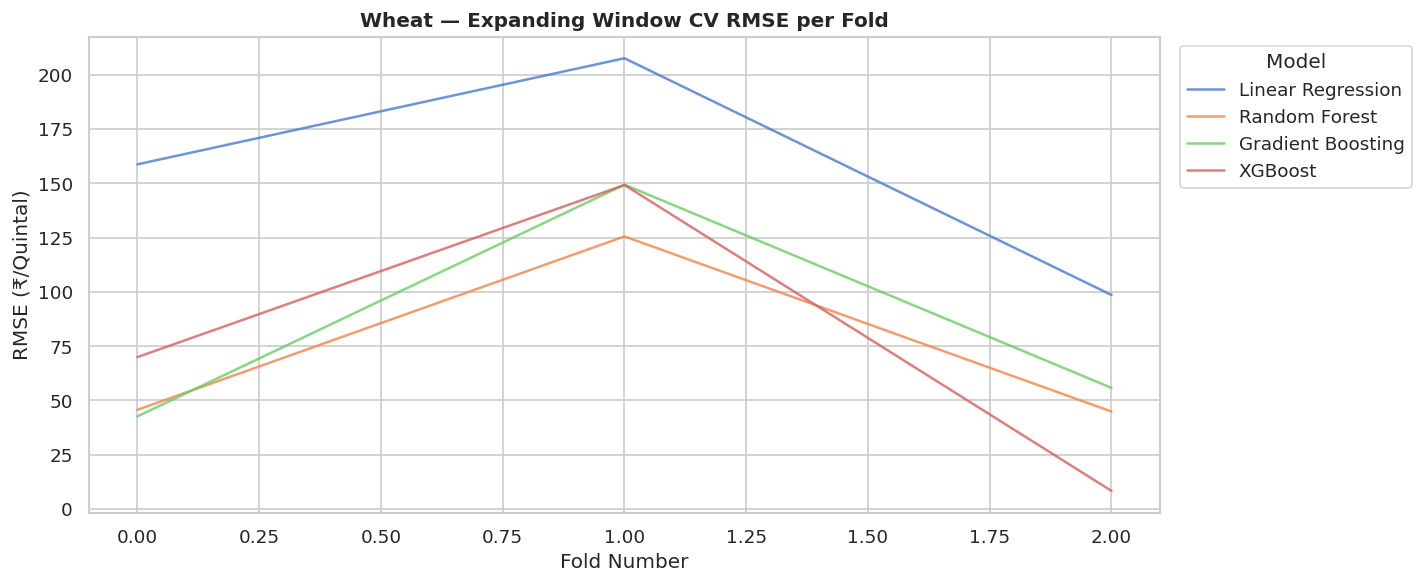

In [23]:
# Cross Validation RMSE Plot
plt.figure(figsize=(12, 5))
for name, rmse_list in cv_results.items():
    plt.plot(rmse_list, label=name, linewidth=1.5, alpha=0.8)
plt.title(f'{COMMODITY} — Expanding Window CV RMSE per Fold',
          fontweight='bold')
plt.xlabel('Fold Number')
plt.ylabel('RMSE (₹/Quintal)')
plt.legend(title='Model', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_MODEL + f'ml_{COMMODITY}_cv_rmse.png',
            bbox_inches='tight')
plt.show()

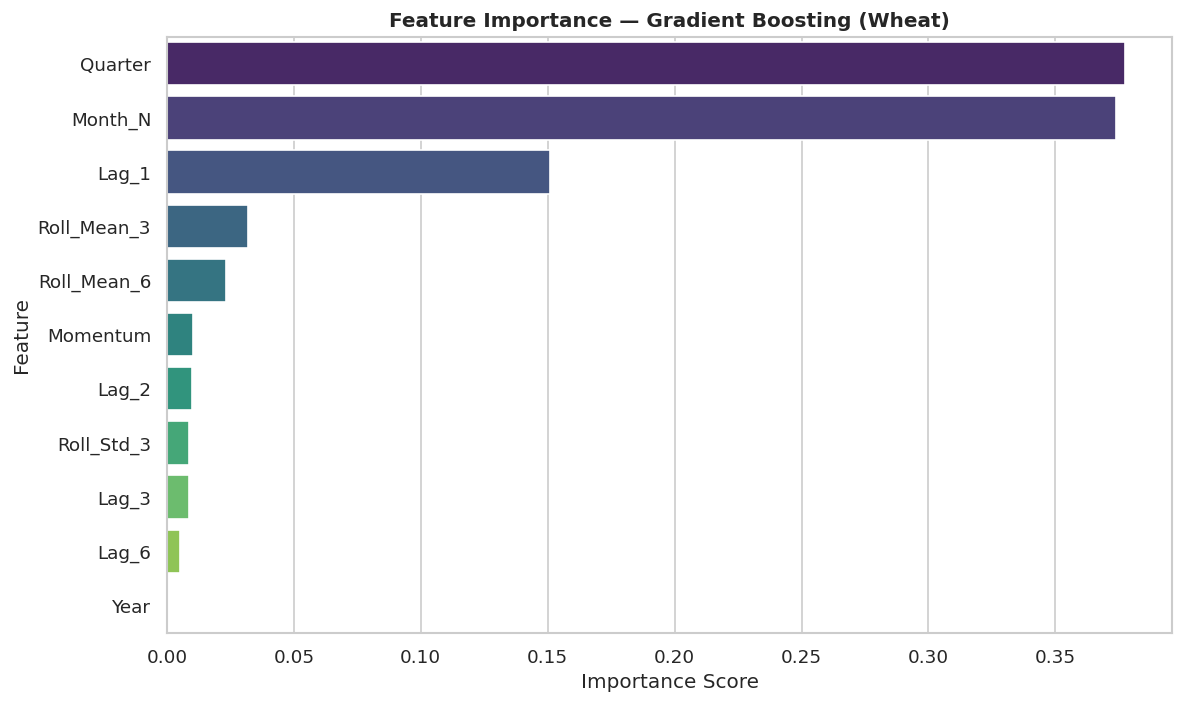

Feature Importance:
    Feature  Importance
    Quarter      0.3773
    Month_N      0.3738
      Lag_1      0.1510
Roll_Mean_3      0.0318
Roll_Mean_6      0.0234
   Momentum      0.0102
      Lag_2      0.0097
 Roll_Std_3      0.0088
      Lag_3      0.0087
      Lag_6      0.0052
       Year      0.0001

Interpretation:
- Lag features (Lag_1, Lag_2, Lag_3) dominate importance,
  confirming that recent prices are the strongest predictor
  of future prices.
- Rolling mean features capture medium-term trends.
- Month and Quarter encode seasonal information.
- Momentum captures the direction of recent price movement.
    


In [24]:
# Feature Importance
best_model      = models[best_ml_name]
best_model.fit(X_train, y_train)

if hasattr(best_model, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature'   : FEATURES,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df,
                x='Importance', y='Feature',
                palette='viridis')
    plt.title(f'Feature Importance — {best_ml_name} ({COMMODITY})',
              fontweight='bold')
    plt.xlabel('Importance Score')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.savefig(IMAGES_MODEL +
                f'ml_{COMMODITY}_feature_importance.png',
                bbox_inches='tight')
    plt.show()

    print("Feature Importance:")
    print(importance_df.to_string(index=False))
    print("""
Interpretation:
- Lag features (Lag_1, Lag_2, Lag_3) dominate importance,
  confirming that recent prices are the strongest predictor
  of future prices.
- Rolling mean features capture medium-term trends.
- Month and Quarter encode seasonal information.
- Momentum captures the direction of recent price movement.
    """)
else:
    # Linear Regression coefficients
    coef_df = pd.DataFrame({
        'Feature'    : FEATURES,
        'Coefficient': best_model.coef_
    }).sort_values('Coefficient', key=abs, ascending=False)
    print("Linear Regression Coefficients:")
    print(coef_df.to_string(index=False))

## Section 11 — 6-Month Future Price Forecast

Using the best performing model, we forecast the next
6 months of Wheat modal prices beyond the dataset.

### Forecasting Approach
- Recursive forecasting: each predicted value becomes
  the input for the next prediction
- Lag features are updated with previous predictions
- Rolling features are recalculated from updated history

### Limitations
- Forecast uncertainty increases with each step ahead
- No external shocks (weather, policy) are modelled
- The 6-month horizon is at the edge of reliable forecasting
  for monthly price data

In [27]:
# 6-Month Future Forecast
best_model.fit(X_train, y_train)

forecast_prices = []
forecast_months = []
last_date       = ts['Month'].max()

for i in range(1, 7):
    next_month = last_date + pd.DateOffset(months=i)

    lag1 = forecast_prices[-1] if len(forecast_prices) >= 1 \
           else float(ts_feat['Modal_Price'].iloc[-1])
    lag2 = forecast_prices[-2] if len(forecast_prices) >= 2 \
           else float(ts_feat['Modal_Price'].iloc[-2])
    lag3 = forecast_prices[-3] if len(forecast_prices) >= 3 \
           else float(ts_feat['Modal_Price'].iloc[-3])
    lag6 = forecast_prices[-6] if len(forecast_prices) >= 6 \
           else float(ts_feat['Modal_Price'].iloc[-(6-len(forecast_prices))])

    recent = ([float(ts_feat['Modal_Price'].iloc[-3]),
               float(ts_feat['Modal_Price'].iloc[-2]),
               float(ts_feat['Modal_Price'].iloc[-1])] +
               forecast_prices)

    roll_mean_3 = np.mean(recent[-3:])
    roll_mean_6 = np.mean(recent[-6:]) if len(recent) >= 6 \
                  else np.mean(recent)
    roll_std_3  = np.std(recent[-3:])
    momentum    = lag1 - lag3

    new_row = pd.DataFrame([{
        'Year'       : next_month.year,
        'Month_N'    : next_month.month,
        'Quarter'    : (next_month.month - 1) // 3 + 1,
        'Lag_1'      : lag1,
        'Lag_2'      : lag2,
        'Lag_3'      : lag3,
        'Lag_6'      : lag6,
        'Roll_Mean_3': roll_mean_3,
        'Roll_Mean_6': roll_mean_6,
        'Roll_Std_3' : roll_std_3,
        'Momentum'   : momentum
    }])

    pred_price = best_model.predict(new_row)[0]
    forecast_prices.append(float(pred_price))
    forecast_months.append(next_month)

forecast_df = pd.DataFrame({
    'Month'           : forecast_months,
    'Forecasted_Price': np.round(forecast_prices, 2)
})

print(f"6-Month Forecast — {COMMODITY} ({best_ml_name})")
print("═"*40)
print(forecast_df.to_string(index=False))

6-Month Forecast — Wheat (Gradient Boosting)
════════════════════════════════════════
     Month  Forecasted_Price
2026-06-01         2475.4300
2026-07-01         2482.7400
2026-08-01         2482.3600
2026-09-01         2513.0600
2026-10-01         2703.2700
2026-11-01         2738.6100


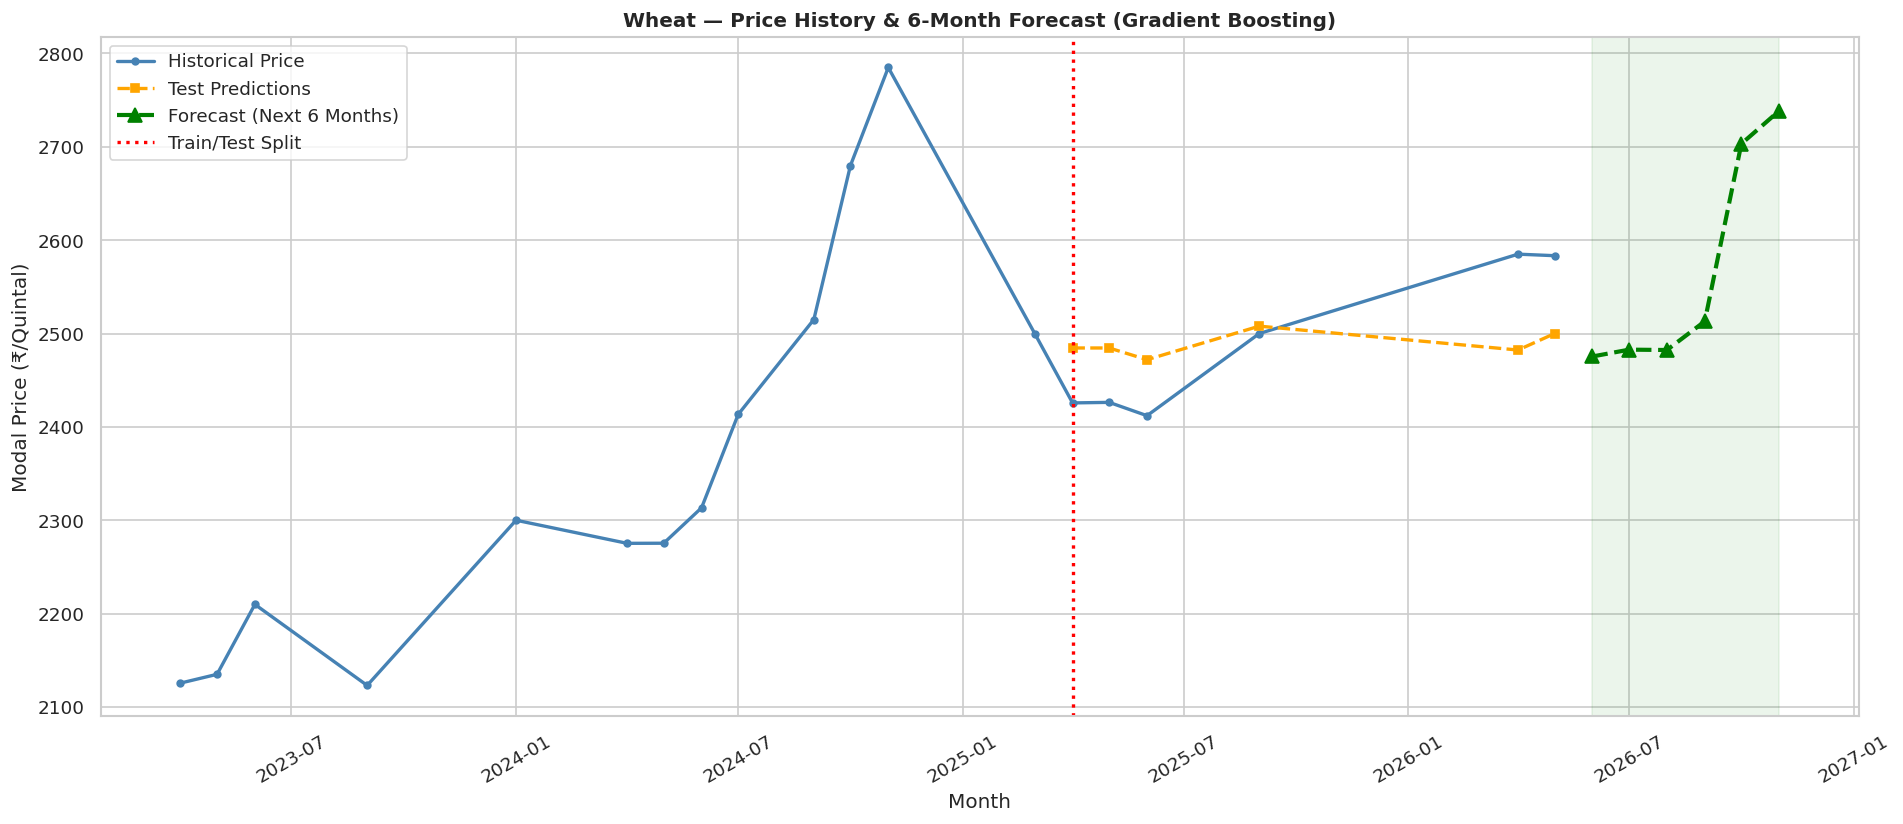

In [28]:
# Full History + Forecast Plot
plt.figure(figsize=(16, 7))

# Historical prices
plt.plot(ts['Month'], ts['Modal_Price'],
         color='steelblue', linewidth=2,
         marker='o', markersize=4,
         label='Historical Price')

# Test predictions
plt.plot(test['Month'],
         all_preds[best_ml_name],
         color='orange', linewidth=2,
         marker='s', markersize=5,
         linestyle='--',
         label='Test Predictions')

# Future forecast
plt.plot(forecast_df['Month'],
         forecast_df['Forecasted_Price'],
         color='green', linewidth=2.5,
         marker='^', markersize=8,
         linestyle='--',
         label='Forecast (Next 6 Months)')

# Shade forecast region
plt.axvspan(forecast_df['Month'].iloc[0],
            forecast_df['Month'].iloc[-1],
            alpha=0.08, color='green')

# Mark train/test split
plt.axvline(x=test['Month'].iloc[0],
            color='red', linestyle=':',
            linewidth=2, label='Train/Test Split')

plt.title(f'{COMMODITY} — Price History & 6-Month Forecast '
          f'({best_ml_name})', fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Modal Price (₹/Quintal)')
plt.legend(loc='upper left')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(IMAGES_MODEL + f'ml_{COMMODITY}_forecast.png',
            bbox_inches='tight')
plt.show()

In [29]:
# Hypothesis H3 Final Result
print("═"*55)
print("    HYPOTHESIS H3 — FORECAST vs BASELINE")
print("═"*55)
print(f"Naive Baseline RMSE   : ₹{naive_rmse:.2f}")
print(f"Best ML Model         : {best_ml_name}")
print(f"Best ML RMSE          : ₹{best_ml_rmse:.2f}")
print(f"RMSE Improvement      : {improvement:.2f}%")
print()
if best_ml_rmse < naive_rmse:
    print("H3 SUPPORTED")
    print("   ML model outperforms the naive baseline.")
    print("   The improvement justifies the complexity of")
    print("   the machine learning approach.")
else:
    print("H3 NOT SUPPORTED")
    print("   The naive baseline performs equally well or better.")
    print("   This may indicate insufficient training data or")
    print("   that prices follow a near-random walk pattern.")
print("═"*55)

═══════════════════════════════════════════════════════
    HYPOTHESIS H3 — FORECAST vs BASELINE
═══════════════════════════════════════════════════════
Naive Baseline RMSE   : ₹58.75
Best ML Model         : Gradient Boosting
Best ML RMSE          : ₹68.34
RMSE Improvement      : -16.33%

H3 NOT SUPPORTED
   The naive baseline performs equally well or better.
   This may indicate insufficient training data or
   that prices follow a near-random walk pattern.
═══════════════════════════════════════════════════════


In [32]:
# Train & Save Models for ALL Valid Commodities
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (RandomForestRegressor,
                               GradientBoostingRegressor)
from sklearn.metrics import mean_squared_error
import xgboost as xgb
import joblib
import json

MIN_ROWS  = 20
TEST_SIZE = 6

FEATURES = ['Year', 'Month_N', 'Quarter',
            'Lag_1', 'Lag_2', 'Lag_3', 'Lag_6',
            'Roll_Mean_3', 'Roll_Mean_6',
            'Roll_Std_3', 'Momentum']
TARGET = 'Modal_Price'

def create_features(df_ts):
    df_ts = df_ts.copy()
    df_ts['Year']        = df_ts['Month'].dt.year
    df_ts['Month_N']     = df_ts['Month'].dt.month
    df_ts['Quarter']     = df_ts['Month'].dt.quarter
    for lag in [1, 2, 3, 6]:
        df_ts[f'Lag_{lag}'] = df_ts['Modal_Price'].shift(lag)
    df_ts['Roll_Mean_3'] = df_ts['Modal_Price']\
                            .shift(1).rolling(3).mean()
    df_ts['Roll_Mean_6'] = df_ts['Modal_Price']\
                            .shift(1).rolling(6).mean()
    df_ts['Roll_Std_3']  = df_ts['Modal_Price']\
                            .shift(1).rolling(3).std()
    df_ts['Momentum']    = df_ts['Modal_Price'].shift(1) - \
                           df_ts['Modal_Price'].shift(3)
    df_ts.dropna(inplace=True)
    df_ts.reset_index(drop=True, inplace=True)
    return df_ts

# Get all valid commodities with enough data
valid_commodities = monthly_df.groupby('Commodity')['Month']\
                               .count()\
                               .where(lambda x: x >= MIN_ROWS)\
                               .dropna().index.tolist()

print(f"Total valid commodities : {len(valid_commodities)}")
print(valid_commodities)

all_model_stats = {}
trained  = 0
skipped  = 0

for commodity in valid_commodities:
    ts_c = monthly_df[monthly_df['Commodity'] == commodity]\
               .sort_values('Month').reset_index(drop=True)

    ts_feat_c = create_features(ts_c)

    if len(ts_feat_c) < TEST_SIZE + 10:
        print(f"  Skipped (not enough rows) : {commodity}")
        skipped += 1
        continue

    train_c = ts_feat_c.iloc[:-TEST_SIZE]
    test_c  = ts_feat_c.iloc[-TEST_SIZE:]

    X_train_c = train_c[FEATURES]
    y_train_c = train_c[TARGET]
    X_test_c  = test_c[FEATURES]
    y_test_c  = test_c[TARGET]

    models_c = {
        'Linear Regression' : LinearRegression(),
        'Random Forest'     : RandomForestRegressor(
                                n_estimators=200,
                                random_state=42),
        'Gradient Boosting' : GradientBoostingRegressor(
                                n_estimators=200,
                                random_state=42),
        'XGBoost'           : xgb.XGBRegressor(
                                n_estimators=200,
                                random_state=42,
                                verbosity=0)
    }

    all_rmse   = {}
    best_name  = None
    best_rmse  = float('inf')
    best_model_c = None

    for name, model_c in models_c.items():
        model_c.fit(X_train_c, y_train_c)
        preds_c = model_c.predict(X_test_c)
        rmse_c  = np.sqrt(mean_squared_error(
                            y_test_c, preds_c))
        all_rmse[name] = round(rmse_c, 2)

        # Save each model separately
        safe_comm  = commodity\
                        .replace('/', '_')\
                        .replace(' ', '_')\
                        .replace('(', '')\
                        .replace(')', '')
        safe_model = name.replace(' ', '_')
        joblib.dump(model_c,
                    MODELS_PATH +
                    f'model_{safe_comm}_{safe_model}.pkl')

        if rmse_c < best_rmse:
            best_rmse    = rmse_c
            best_name    = name
            best_model_c = model_c

    # Save best model separately
    joblib.dump(best_model_c,
                MODELS_PATH + f'model_{safe_comm}.pkl')

    # Store stats for dashboard
    all_model_stats[commodity] = {
        'safe_name'  : safe_comm,
        'best_model' : best_name,
        'all_rmse'   : all_rmse,
        'avg_price'  : float(ts_feat_c['Modal_Price'].mean()),
        'min_price'  : float(ts_feat_c['Modal_Price'].min()),
        'max_price'  : float(ts_feat_c['Modal_Price'].max()),
        'last_values': ts_feat_c['Modal_Price']\
                                 .tail(6).tolist(),
        'last_lag1'  : float(ts_feat_c['Modal_Price'].iloc[-1]),
        'last_lag2'  : float(ts_feat_c['Modal_Price'].iloc[-2]),
        'last_lag3'  : float(ts_feat_c['Modal_Price'].iloc[-3]),
        'last_lag6'  : float(ts_feat_c['Modal_Price'].iloc[-6]),
        'roll_std3'  : float(ts_feat_c['Modal_Price']\
                                        .tail(3).std()),
        'rmse'       : round(best_rmse, 2)
    }

    trained += 1
    print(f"  Done: {commodity:<40} "
          f"Best: {best_name:<25} "
          f"RMSE: ₹{best_rmse:.0f}")

# Save all stats in one JSON
with open(MODELS_PATH + 'all_model_stats.json', 'w') as f:
    json.dump(all_model_stats, f)

# Save feature list
with open(MODELS_PATH + 'model_features.json', 'w') as f:
    json.dump(FEATURES, f)

print(f"\n{'═'*55}")
print(f"  Trained  : {trained}")
print(f"  Skipped  : {skipped}")
print(f"  Saved    : all_model_stats.json → {MODELS_PATH}")
print(f"  Saved    : model_features.json  → {MODELS_PATH}")
print(f"{'═'*55}")

Total valid commodities : 55
['Apple', 'Bajra(Pearl Millet/Cumbu)', 'Banana', 'Barley (Jau)', 'Beetroot', 'Bengal Gram(Gram)(Whole)', 'Bhindi(Ladies Finger)', 'Bitter gourd', 'Bottle gourd', 'Brinjal', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Chikoos(Sapota)', 'Coriander(Leaves)', 'Cotton', 'Cucumbar(Kheera)', 'Garlic', 'Ginger(Dry)', 'Ginger(Green)', 'Grapes', 'Green Chilli', 'Green Gram (Moong)(Whole)', 'Guar', 'Guava', 'Indian Colza(Sarson)', 'Karbuja(Musk Melon)', 'Kinnow', 'Leafy Vegetable', 'Lemon', 'Long Melon(Kakri)', 'Mango', 'Methi(Leaves)', 'Mousambi(Sweet Lime)', 'Mustard', 'Onion', 'Onion Green', 'Orange', 'Paddy(Dhan)(Basmati)', 'Paddy(Dhan)(Common)', 'Peas Wet', 'Peas cod', 'Pomegranate', 'Potato', 'Pumpkin', 'Raddish', 'Ridgeguard(Tori)', 'Round gourd', 'Spinach', 'Sponge gourd', 'Squash(Chappal Kadoo)', 'Tinda', 'Tomato', 'Water Melon']
  Done: Apple                                    Best: XGBoost                   RMSE: ₹1150
  Done: Bajra(Pearl Millet/Cumbu)

In [33]:
# Save Wheat-Specific Outputs
# These are specifically needed for the Wheat forecast
# tab in the dashboard

# Save forecast
forecast_df['Commodity'] = COMMODITY
forecast_df['Model']     = best_ml_name
forecast_df.to_csv(MODELS_PATH + f'forecast_{COMMODITY}.csv',
                   index=False)

# Save model results
scorecard_df.to_csv(MODELS_PATH +
                    f'model_results_{COMMODITY}.csv')

# Save test predictions
test_preds_df = test[['Month', 'Modal_Price']].copy()
test_preds_df['Predicted'] = all_preds[best_ml_name]
test_preds_df['Commodity'] = COMMODITY
test_preds_df.to_csv(MODELS_PATH +
                     f'test_predictions_{COMMODITY}.csv',
                     index=False)

# Save cross validation results
cv_summary.to_csv(MODELS_PATH + 'cv_results.csv',
                  index=False)

print(" Wheat-specific outputs saved")
print(f"   forecast_{COMMODITY}.csv           → {MODELS_PATH}")
print(f"   model_results_{COMMODITY}.csv      → {MODELS_PATH}")
print(f"   test_predictions_{COMMODITY}.csv   → {MODELS_PATH}")
print(f"   cv_results.csv                     → {MODELS_PATH}")

 Wheat-specific outputs saved
   forecast_Wheat.csv           → /content/drive/MyDrive/Haryana_Mandi_Project/Models/
   model_results_Wheat.csv      → /content/drive/MyDrive/Haryana_Mandi_Project/Models/
   test_predictions_Wheat.csv   → /content/drive/MyDrive/Haryana_Mandi_Project/Models/
   cv_results.csv                     → /content/drive/MyDrive/Haryana_Mandi_Project/Models/
